# PH 4050  Computational Electrodynamics - Lab 5 - Pamudu Amarasinghe

# 1) 1D Helmholtz equation wave equation,  the second derivative
d2f/dt2 = d2f/dx2            

f(0, t) = f(pi, t) = 0.

In [20]:
import numpy as np
from scipy.sparse import diags


L = np.pi  #  [0, pi]
N = 100  
dx = L / N  
dt = 0.95 * dx  # stability condition dt/dx = 0.95
t_max = 300.0  # total time
num_steps = int(t_max / dt)


# Sparse Matrix
r = dt / dx
main_diag = (2 - 2 * r**2) * np.ones(N - 1)
off_diag = (r**2) * np.ones(N - 2)
A = diags([off_diag, main_diag, off_diag], offsets=[-1, 0, 1], format='csr')

print("Sparse matrix representation")
print(A.toarray())  


Sparse matrix representation
[[0.195  0.9025 0.     ... 0.     0.     0.    ]
 [0.9025 0.195  0.9025 ... 0.     0.     0.    ]
 [0.     0.9025 0.195  ... 0.     0.     0.    ]
 ...
 [0.     0.     0.     ... 0.195  0.9025 0.    ]
 [0.     0.     0.     ... 0.9025 0.195  0.9025]
 [0.     0.     0.     ... 0.     0.9025 0.195 ]]


# 3)

<>:41: SyntaxWarning: invalid escape sequence '\p'
<>:42: SyntaxWarning: invalid escape sequence '\p'
<>:50: SyntaxWarning: invalid escape sequence '\o'
<>:53: SyntaxWarning: invalid escape sequence '\o'
<>:41: SyntaxWarning: invalid escape sequence '\p'
<>:42: SyntaxWarning: invalid escape sequence '\p'
<>:50: SyntaxWarning: invalid escape sequence '\o'
<>:53: SyntaxWarning: invalid escape sequence '\o'
C:\Users\Pamudu Amarasinghe\AppData\Local\Temp\ipykernel_11288\502198613.py:41: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(omega[mask], fft_mid[mask], label='Detector: Midpoint ($x=\pi/2$)')
C:\Users\Pamudu Amarasinghe\AppData\Local\Temp\ipykernel_11288\502198613.py:42: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(omega[mask], fft_left[mask], label='Detector: Left ($x=\pi/5$)')
C:\Users\Pamudu Amarasinghe\AppData\Local\Temp\ipykernel_11288\502198613.py:50: SyntaxWarning: invalid escape sequence '\o'
  label='Theoretical $\omega_m$' if m == 1 else '',
C:\Users\Pamu

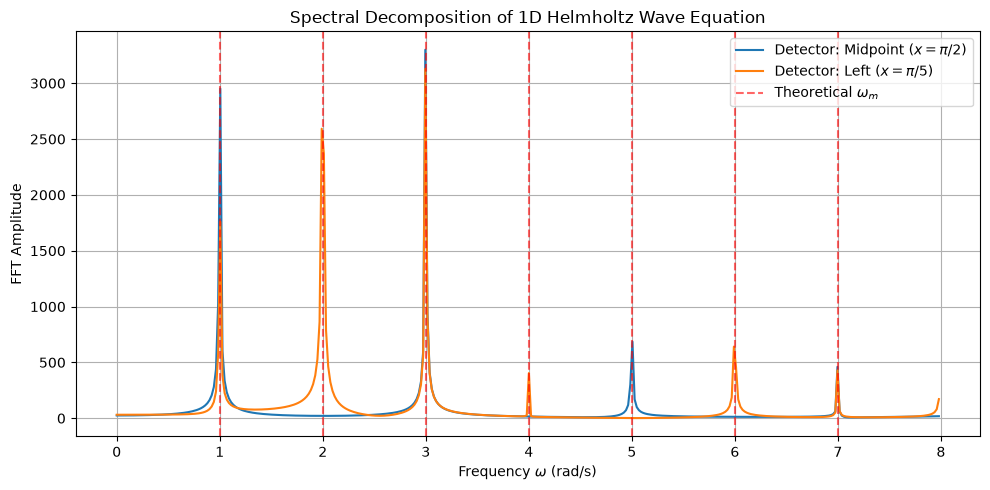

In [ ]:
import matplotlib.pyplot as plt
from scipy.fft import fft

np.random.seed(42)
f_even = np.random.rand(N - 1) 
f_odd = np.random.rand(N - 1)  



idx_mid = N // 2 - 1  # x = pi/2
idx_left = N // 5 - 1  # x = pi/5


sig_mid = np.zeros(num_steps)
sig_left = np.zeros(num_steps)
sig_mid[0], sig_left[0] = f_even[idx_mid], f_even[idx_left]
sig_mid[1], sig_left[1] = f_odd[idx_mid], f_odd[idx_left]


for n in range(1, num_steps - 1):
  if n % 2 == 1:
    f_next = A @ f_odd - f_even
    f_even = f_next
    sig_mid[n + 1] = f_even[idx_mid]
    sig_left[n + 1] = f_even[idx_left]
  else:
    f_next = A @ f_even - f_odd
    f_odd = f_next
    sig_mid[n + 1] = f_odd[idx_mid]
    sig_left[n + 1] = f_odd[idx_left]



T_total = num_steps * dt
omega = (2 * np.pi / T_total) * np.arange(num_steps)
fft_mid = np.abs(fft(sig_mid))
fft_left = np.abs(fft(sig_left))

# Plot spectrum vs  eigenfrequencies
plt.figure(figsize=(10, 5))
mask = (omega >= 0) & (omega <= 8)
plt.plot(omega[mask], fft_mid[mask], label='Detector: Midpoint ($x=\pi/2$)')
plt.plot(omega[mask], fft_left[mask], label='Detector: Left ($x=\pi/5$)')

for m in range(1, 8):
  plt.axvline(
      m,
      color='r',
      linestyle='--',
      alpha=0.6,
      label='Theoretical $\omega_m$' if m == 1 else '',
  )

plt.xlabel('Frequency $\omega$ (rad/s)')
plt.ylabel('FFT Amplitude')
plt.title('Spectral Decomposition of 1D Helmholtz Wave Equation')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 8)spectrum broadning when the time interval is (0, 20*pi) and (0, 21*pi)

In [27]:
def get_spectrum(t_end):
  steps = int(t_end / dt)
  T = steps * dt
  fe, fo = f_even_init.copy(), f_odd_init.copy()
  history = np.zeros(steps)
  history[0], history[1] = fe[idx_mid], fo[idx_mid]

  for n in range(1, steps - 1):
    if n % 2 == 1:
      fe = A @ fo - fe
      history[n + 1] = fe[idx_mid]
    else:
      fo = A @ fe - fo
      history[n + 1] = fo[idx_mid]

  w = (2 * np.pi / T) * np.arange(steps)
  return w, np.abs(fft(history))


f_even_init, f_odd_init = np.random.rand(N - 1), np.random.rand(N - 1)
w_20, fft_20 = get_spectrum(20 * np.pi)
w_21, fft_21 = get_spectrum(21 * np.pi)

print("Time interval ")
print("\n 20pi \n", w_20,fft_20)
print("\n 21pi \n", w_20,fft_20)



Time interval 

 20pi 
 [0.00000000e+00 1.00012502e-01 2.00025003e-01 ... 2.10226278e+02
 2.10326291e+02 2.10426303e+02] [0.09137238 0.0947597  0.10497721 ... 0.12244825 0.10497721 0.0947597 ]

 21pi 
 [0.00000000e+00 1.00012502e-01 2.00025003e-01 ... 2.10226278e+02
 2.10326291e+02 2.10426303e+02] [0.09137238 0.0947597  0.10497721 ... 0.12244825 0.10497721 0.0947597 ]


The Discrete Fourier Transform assumes infinite periodic repetition of the finite-length time series [0, T].When T = 20pi, the window duration spans an exact integer number of periods for all modes (omega_m = 1, 2, 3 ....). The signal value and derivative at t = T seamlessly match t = 0.When $T = 21pi, the window truncates modes mid-cycle (at half-period phases, e.g., $10.5$ cycles for omega_1 = 1). Periodically repeating this truncated signal introduces artificial step-discontinuities at the boundaries, smearing energy across a wide range of frequencies